# Contador preciso (con un único lock)

Este notebook lee `results_lock.csv`, generado por `./benchmark_precise_counter`, y grafica el tiempo en función del número de hilos. Cada hilo incrementa un millón de veces el mismo contador, protegido por un `pthread_mutex_t`.

> **Importante:** el notebook debe ejecutarse desde esta carpeta, donde está `results_lock.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("results_lock.csv")
# Speedup ideal = 1: con N hilos se hace N veces más trabajo en el mismo tiempo
df["T(N) / T(1)"] = (df["Time(s)"] / df["Time(s)"].iloc[0]).round(1)
df

,Threads,Time(s),Expected,Actual,T(N) / T(1)
0,1,0.0346,1000000,1000000,1.0
1,2,0.1373,2000000,2000000,4.0
2,4,0.2839,4000000,4000000,8.2
3,8,0.6336,8000000,8000000,18.3
4,16,1.3247,16000000,16000000,38.3


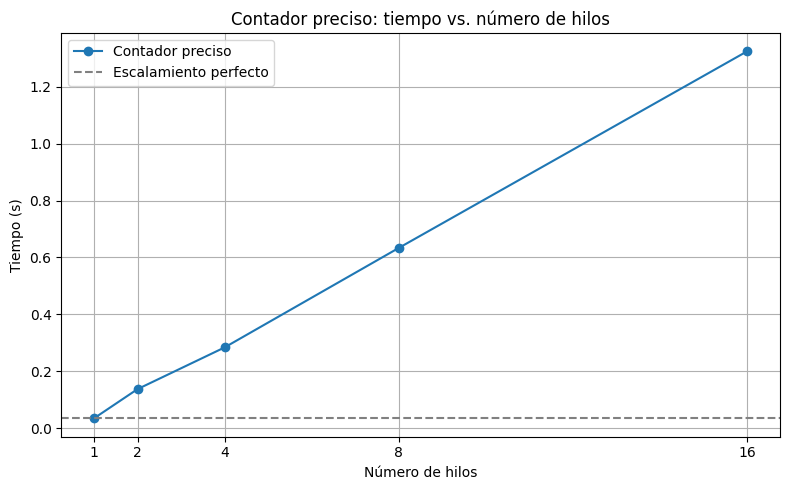

In [2]:
plt.figure(figsize=(8, 5))
plt.plot(df["Threads"], df["Time(s)"], marker="o", label="Contador preciso")
plt.axhline(df["Time(s)"].iloc[0], color="gray", linestyle="--", label="Escalamiento perfecto")
plt.xlabel("Número de hilos")
plt.ylabel("Tiempo (s)")
plt.title("Contador preciso: tiempo vs. número de hilos")
plt.xticks(df["Threads"])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Observaciones

- El valor obtenido (`Actual`) coincide con el esperado en todas las filas: el mutex elimina la race condition.
- Con N hilos se hace N veces más trabajo. Si los hilos trabajaran en paralelo, el tiempo se mantendría cerca de la línea gris (escalamiento perfecto, diapositivas p. 13). En cambio, el tiempo crece con el número de hilos: el lock obliga a que los incrementos se hagan de a uno, y además los hilos compiten por adquirirlo.
- La columna `T(N) / T(1)` muestra cuántas veces más tarda el programa con N hilos que con uno.

## Conclusión

El lock garantiza la corrección, pero el contador **escala pobremente** (diapositivas p. 12). Esa es la motivación del contador aproximado (`../sloppy_counter/`).